out # From Part 1 Notebook

In [25]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [26]:
import sys
import os
import os.path as op

sys.path.append(op.abspath(""))  

# Load FSL inside Neurodesk (as in the labs)
import module as lmod
await lmod.purge(force=True)
await lmod.load('fsl/6.0.7.18')
await lmod.list()

from utils import loadFSL          # utils.py copied from labs 
loadFSL()
os.environ["FSLOUTPUTTYPE"] = "NIFTI_GZ"   # every FSL output as .nii.gz

import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from nilearn import plotting, image

from helpers import (find_one, check_tools, run, needs, describe,
                     center_of_mass_world, tissue_volumes, spatial_corr, save_fig)

check_tools("fslreorient2std", "bet", "fast", "flirt", "fnirt", "applywarp")

FSLDIR = /cvmfs/neurodesk.ardc.edu.au/containers/fsl_6.0.7.18_20250928/fsl_6.0.7.18_20250928.simg/opt/fsl-6.0.7.18/
All tools found: fslreorient2std, bet, fast, flirt, fnirt, applywarp


In [27]:
FORCE = False   # True = recompute every step even if its outputs already exist
ANAT_KW = dict(draw_cross=False, colorbar=False)   # common style for brain figures

PROJECT_ROOT = op.abspath("")      
DATA_DIR = op.join(PROJECT_ROOT, "data")
ANAT_DIR = op.join(PROJECT_ROOT, "derivatives", "anat")
FUNC_DIR = op.join(PROJECT_ROOT, "derivatives", "func")
FIG_DIR  = op.join(PROJECT_ROOT, "figures")
for d in (ANAT_DIR, FUNC_DIR, FIG_DIR):
    os.makedirs(d, exist_ok=True)

# Raw data (searched recursively)
T1_RAW   = find_one(DATA_DIR, "T1w.nii.gz")
FMRI_RAW = find_one(DATA_DIR, "tfMRI_LANGUAGE_LR.nii.gz")
EVENTS   = find_one(DATA_DIR, "tfMRI_LANGUAGE_LR_task_onsets.csv")

# MNI152 templates shipped with FSL
STD = op.join(os.environ["FSLDIR"], "data", "standard")
MNI_1MM            = op.join(STD, "MNI152_T1_1mm.nii.gz")
MNI_1MM_BRAIN      = op.join(STD, "MNI152_T1_1mm_brain.nii.gz")
MNI_1MM_BRAIN_MASK = op.join(STD, "MNI152_T1_1mm_brain_mask.nii.gz")
MNI_2MM            = op.join(STD, "MNI152_T1_2mm.nii.gz")
MNI_2MM_BRAIN      = op.join(STD, "MNI152_T1_2mm_brain.nii.gz")
MNI_2MM_MASK_DIL   = op.join(STD, "MNI152_T1_2mm_brain_mask_dil.nii.gz")

for p in (T1_RAW, FMRI_RAW, EVENTS):
    print(op.relpath(p, PROJECT_ROOT))

data/T1w.nii.gz
data/tfMRI_LANGUAGE_LR.nii.gz
data/tfMRI_LANGUAGE_LR_task_onsets.csv


In [28]:
for p in (T1_RAW, FMRI_RAW, MNI_1MM):
    describe(p)
    print()

events = pd.read_csv(EVENTS)
events.head(10)

T1w.nii.gz
  shape:       (260, 311, 260)
  voxel size:  (0.7, 0.7, 0.7)  (4th value = TR in s for 4D data)
  orientation: LAS
  dtype:       float32

tfMRI_LANGUAGE_LR.nii.gz
  shape:       (91, 109, 91, 316)
  voxel size:  (2.0, 2.0, 2.0, 0.72)  (4th value = TR in s for 4D data)
  orientation: LAS
  dtype:       float32

MNI152_T1_1mm.nii.gz
  shape:       (182, 218, 182)
  voxel size:  (1.0, 1.0, 1.0)  (4th value = TR in s for 4D data)
  orientation: LAS
  dtype:       int16



,onset,duration,trial_type
0,0.241,28.270,story
1,0.241,20.445,present_story
2,21.192,1.161,question_story
3,25.550,2.961,response_story
4,28.696,0.727,cue
5,30.095,5.667,present_math
6,30.095,12.241,math
7,35.946,3.391,question_math
8,39.371,2.965,response_math
9,42.570,5.453,present_math


# 1.3 General Linear Model

The GLM let us fit multiples linear regression models in a model. Matrix formulation :
$X = YB + E$, with $X$ the multivariates observations, $Y$ the design matrix containging conditions and covariates, $B$ the parameter weigths, and $E$ the residual error.

The beta parameters are estimated using Ordinary Least Square (OLS).

### 1.3.a Building experimental design matrix
Building the experimental design matrix of the GLM from the events file. The regressors obtained from the events file are the task-related regressors.

Nuisance regressors: To mitigate any motion artifacts the motion confounds from the previous preprocessing were taken into account (rotation and translation). A cosine drift model was added to account for any drift occurring over time.

In [ ]:
from nilearn.glm.first_level import make_first_level_design_matrix, FirstLevelModel

TR = 0.72
FMRI_SMOOTH  = op.join(FUNC_DIR, "tfMRI_LANGUAGE_LR_mc_smooth.nii.gz")
FUNC_MASK    = op.join(FUNC_DIR, "func_brain_mask.nii.gz")
CONFOUNDS    = op.join(FUNC_DIR, "func_motion_confounds.csv")
motion = pd.read_csv(CONFOUNDS)

# Specification of GLM
fmri_glm = FirstLevelModel(t_r=TR, # repetition time
                           mask_img=FUNC_MASK,
                           noise_model='ar1', #first level autoregressive noise model
                           standardize=False,
                           hrf_model='spm', #hemodynamic response function
                           drift_model='cosine', #account for drift over time
                           high_pass=.01) # remove dc

# Fit the model to our design and data
fmri_glm = fmri_glm.fit(FMRI_SMOOTH, events,
                        confounds=motion[['rot_x', 'rot_y','rot_z', 'trans_x', 'trans_y', 'trans_z']]) # motion confounds from funct preprocessing

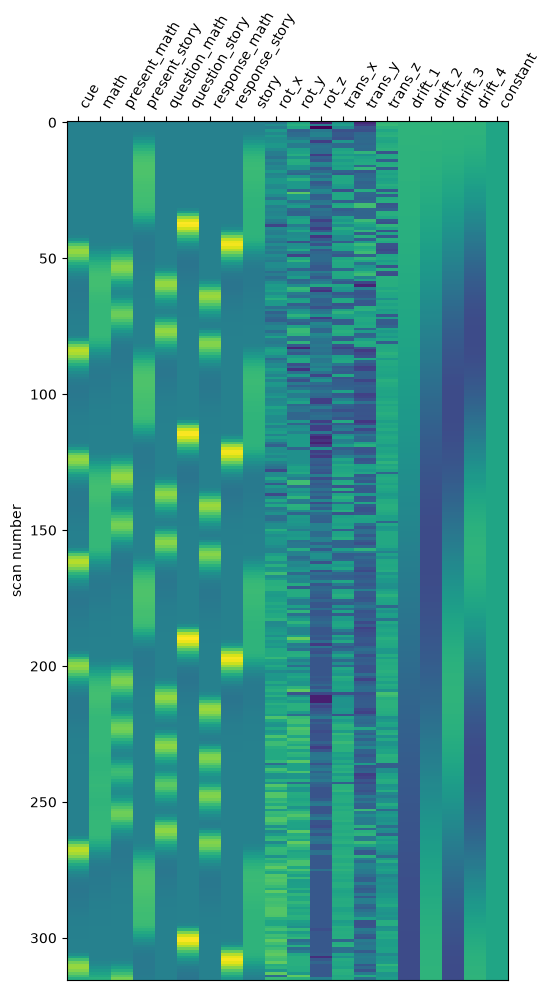

<Figure size 640x480 with 0 Axes>

In [58]:
from nilearn.plotting import plot_design_matrix

GLM_FIG_DIR = op.join(FIG_DIR,'GLM' )
design_mat = fmri_glm.design_matrices_[0]
plot_design_matrix(design_mat)
plt.show()
plt.savefig(op.join(GLM_FIG_DIR, "design_matrix.png"), dpi=300, bbox_inches="tight")

### 1.3.b Correlation matrix between regressors
It is necessary to look at the correlation between regressors as highly correlated regressors result in unstable estimations of the betas. In the case of exact collinearity the GLM is unable to be fitted. 

With the design matrix specified previously the task specific regressors are more correlected amongst themseleves with the "math" regressor positively correlated with math-related regressors and negatively correlated with story-related regressors, and inveresly. These results are expected. To be exact, the regressors that might be dangerously correlated are math&present_math(~0.75), story&present_story(~0.75), and math-story (negatively, ~-0.8). 

The motion covariates are almost uncorrelated with the task and drift regressors. Amongst themselves there is some light correlation, with trans_x&rot_y (~0.8) and trans_y&trans_z (~-0.6) the most correlated. The drift covariates are uncorrelated among themselves by construction. 

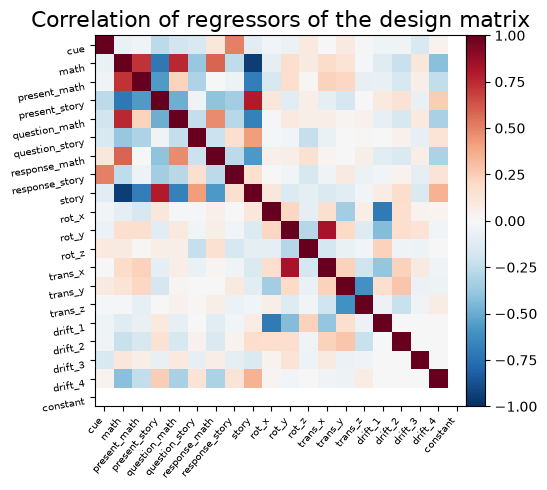

<Figure size 640x480 with 0 Axes>

In [59]:
from nilearn.plotting import plot_matrix
columns = ['cue', 'math','present_math','present_story','question_math','question_story','response_math','response_story', 'story']

corr = design_mat.corr()

plot_matrix(corr,title='Correlation of regressors of the design matrix', labels=list(design_mat.columns),vmin=-1, vmax=1, cmap="RdBu_r")
plt.show()

plt.savefig(op.join(GLM_FIG_DIR, "correlation_regressors.png"), dpi=300, bbox_inches="tight")

### (1.3.a) Adjustement of design matrix
From the correlation analysis the 'math' and 'story' regressors are discarded as they are too highly correlated to the other regressors to guarantee a stable fit. Such that the **final design matrix** is :

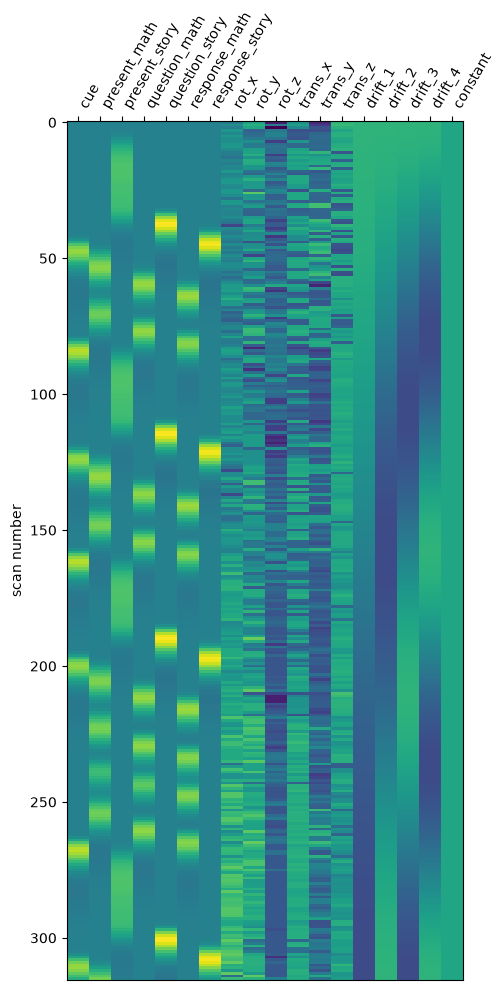

<Figure size 640x480 with 0 Axes>

In [81]:
events_clean = events[~events['trial_type'].isin(['story', 'math'])]

# Fit the model to our clean design and data
fmri_glm = fmri_glm.fit(FMRI_SMOOTH, events_clean,
                        confounds=motion[['rot_x','rot_y','rot_z', 'trans_x', 'trans_y', 'trans_z']]) # motion confounds from funct preprocessing

design_mat = fmri_glm.design_matrices_[0]
plot_design_matrix(design_mat)
plt.show()
plt.savefig(op.join(GLM_FIG_DIR, "design_matrix_clean.png"), dpi=300, bbox_inches="tight")

### (1.3.b) Correlation of new design matrix
We now have a correlation matrix with the dangerous correlations removed:

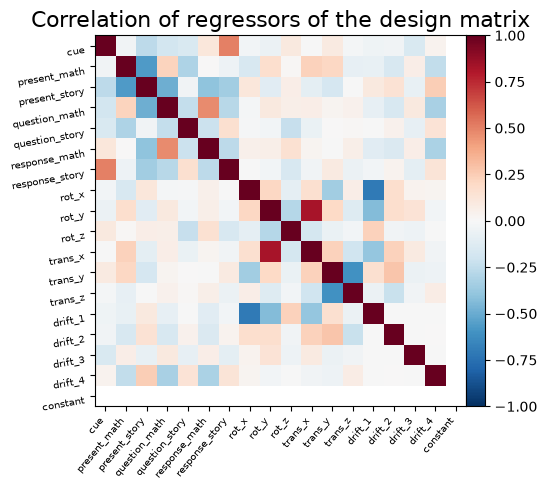

<Figure size 640x480 with 0 Axes>

In [65]:
columns_clean = ['cue','present_math','present_story','question_math','question_story','response_math','response_story']

corr = design_mat.corr()

plot_matrix(corr,title='Correlation of regressors of the design matrix', labels=list(design_mat.columns),vmin=-1, vmax=1, cmap="RdBu_r")
plt.show()

plt.savefig(op.join(GLM_FIG_DIR, "correlation_regressors_clean.png"), dpi=300, bbox_inches="tight")

### 1.3.c Statistical maps of task-related regressors
In point 1.3.a) we already runned the GLM at **first level**. We have only one single subject, there is no group level with random effects to control for. 

The task related regressors are the regressors from the event file. To compute their respective statistical maps, computation of the contrast is done with the contrast being the all zero except for a 1 at the index of the corresponding regressor. Positive activation can indicate task-driven activation, negative activation indicates below baseline activation. \
The z_map obtained is corrected (fdr) for multiple statistical tests due to the multiple voxels.

In [ ]:
# Task related regressors 
task_reg = ['cue','present_math','present_story','question_math','question_story','response_math','response_story']

design_matrix = fmri_glm.design_matrices_[0]

contrasts = {t: np.eye(design_matrix.shape[1])[design_matrix.columns.get_loc(t)] for t in task_reg} # contrast of each task regressor

z_maps = {name: fmri_glm.compute_contrast(vec, output_type="z_score") for name, vec in contrasts.items()}

Correction for multiple statistical tests.

In [ ]:
from nilearn.glm import threshold_stats_img
from nilearn.reporting import get_clusters_table

GLM_DIR = op.join(PROJECT_ROOT, "derivatives", "glm")
STAT_DIR = op.join(GLM_DIR, "statistical_maps")
os.makedirs(STAT_DIR, exist_ok=True)

thresholded, thr = {}, {}
for name, z in z_maps.items():
    thresholded[name], thr[name] = threshold_stats_img(z, alpha=0.05, height_control="fdr", cluster_threshold=10) # correction for multiple voxels
    
    # saving each cluster to csv file
    table = get_clusters_table(z, stat_threshold=thr[name], cluster_threshold=10, two_sided=True)
    table.to_csv(op.join(STAT_DIR, f"{name}_clusters.csv"), index=False)

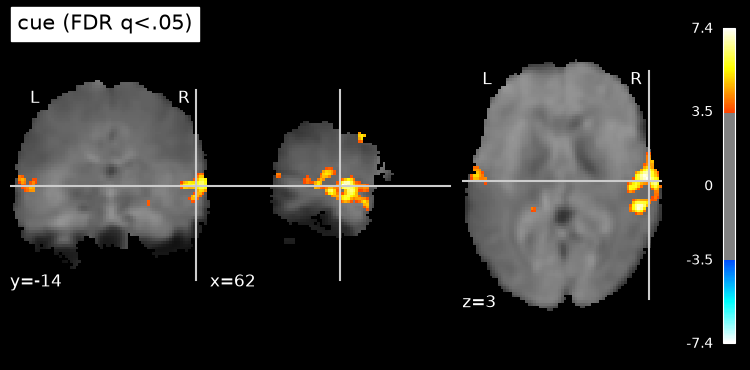

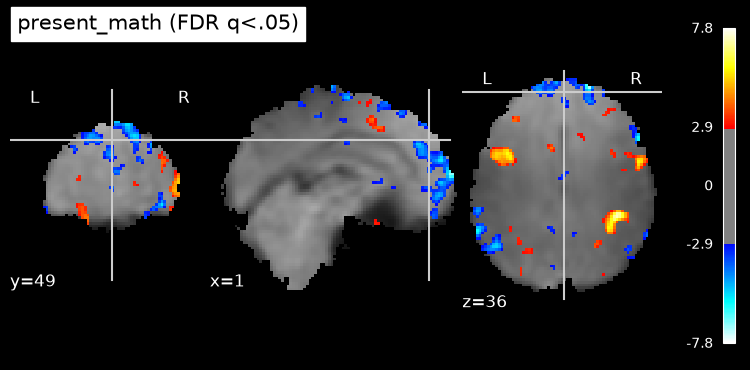

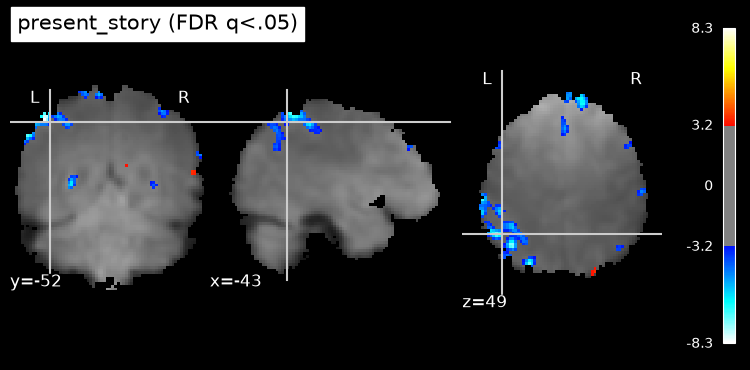

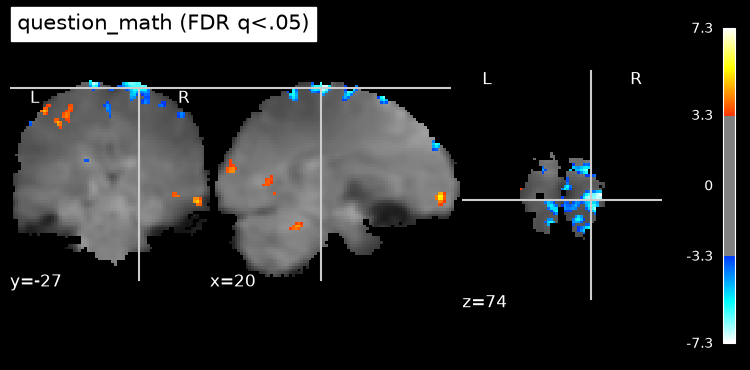

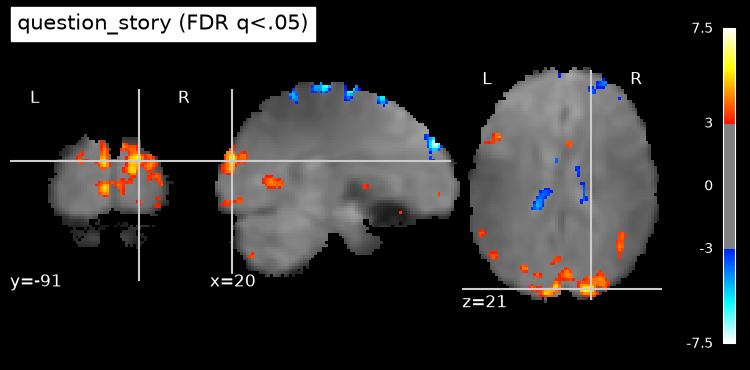

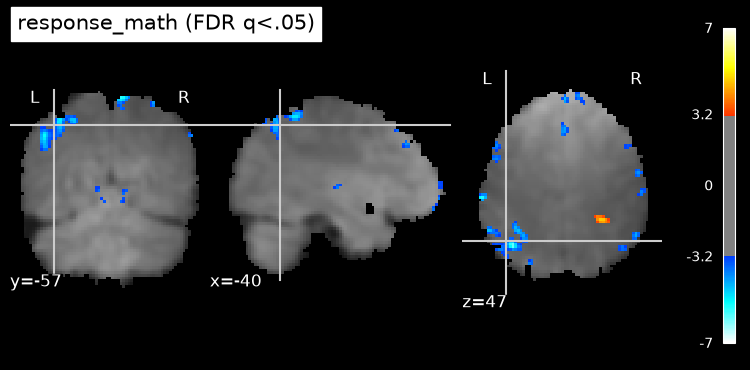

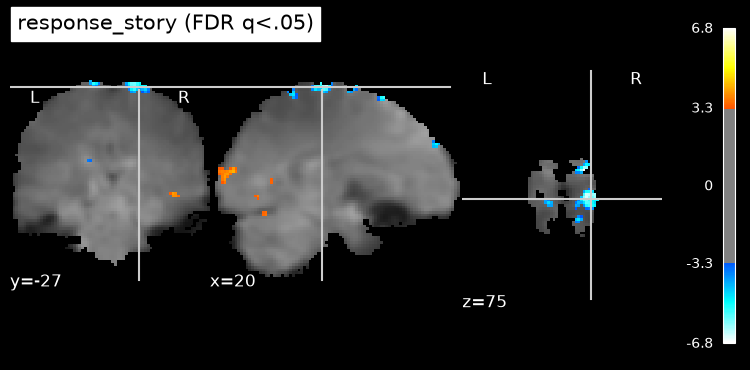

In [84]:
from nilearn import plotting
from nilearn.plotting import plot_stat_map
from nilearn.image import mean_img

GLM_FIG_DIR = op.join(FIG_DIR, 'GLM')
os.makedirs(GLM_FIG_DIR, exist_ok=True)

mean_img_ = mean_img(FMRI_SMOOTH)

for name, img in thresholded.items():
    plotting.plot_stat_map(img, bg_img=mean_img_, threshold=thr[name],
                           display_mode="ortho", cut_coords=None, # None, automatically choose cut
                           title=f"{name} (FDR q<.05)", colorbar=True)
    # saving images 
    plt.savefig(op.join(GLM_FIG_DIR, f"{name}_zmap.png"), dpi=300, bbox_inches="tight")



Every statistical maps except ‘cue’ contains negative clusters at the very top of the brain, this might be due to edge artifacts and not deactivation during these events. 

* Cue: important clusters at the left and right superior temporal gyrus (STG), which is involved in the processing of auditory information. Bigger cluster on the right STG. Clusters at STG are also found in present and question regressors for both math and story. Expected for an auditory task.

* Math-related regressors: clusters at the left intraparietal sulcus (IPS), which is involved in numerical processing. Clusters in the frontal lobe in the event of present math.

* Story-related regressors: clear activation in the occipital region. 

* Question regressors: cluster at the angular gyrus for both math and story question regressors


### 1.3.d Contrast vector and story-vs-math activation map
We are interested in the *difference* between story and math events. To investigate the overall differences, we can define a contrast vector with +1 for every language specific regressors and a -1 for every math specific regressors. Every other unrelated regressors (motion counfounds, drifts) are set to 0. We would get :

$$\large c_{story - math} =
\begin{bmatrix}
0 & -1 & 1 & -1 & 1 & -1 & 1 &0 &...\end{bmatrix}
\begin{bmatrix}
\vec{\beta_{cue}}\\
\vec{\beta_{present\_math}}\\
\vec{\beta_{present\_story}}\\
\vec{\beta_{question\_math}}\\
\vec{\beta_{question\_story}}\\
\vec{\beta_{response\_math}}\\
\vec{\beta_{response\_story}}\\
\vec{\beta_{rot\_x}}\\
\vec{...}\\
\end{bmatrix}$$
In such a set up, positive clusters would match with story activated regions whereas negative clusters would match with math activated regions.

In [ ]:
# define story & math regressors
story_reg = ['present_story','question_story','response_story'] 
math_reg = ['present_math','question_math','response_math']

cols = list(design_matrix.columns)

story_vec = np.zeros(len(cols))
for r in story_reg:
    story_vec[cols.index(r)] = 1.0
    
math_vec = np.zeros(len(cols))
for r in math_reg:
    math_vec[cols.index(r)] = 1.0

story_minus_math = story_vec - math_vec
print('Contrast vector: ',story_minus_math)

Contrast vector:  [ 0. -1.  1. -1.  1. -1.  1.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.]


In [ ]:
z_map = fmri_glm.compute_contrast(story_minus_math, output_type='z_score')

thresholded_sto_min_mat, thr_sto_min_math = threshold_stats_img(z_map, alpha=0.05, height_control="fdr", cluster_threshold=10)
    
# saving to csv file
table = get_clusters_table(z, stat_threshold=thr_sto_min_math, cluster_threshold=10, two_sided=True)
table.to_csv(op.join(STAT_DIR, f"story_minus_math_clusters.csv"), index=False)

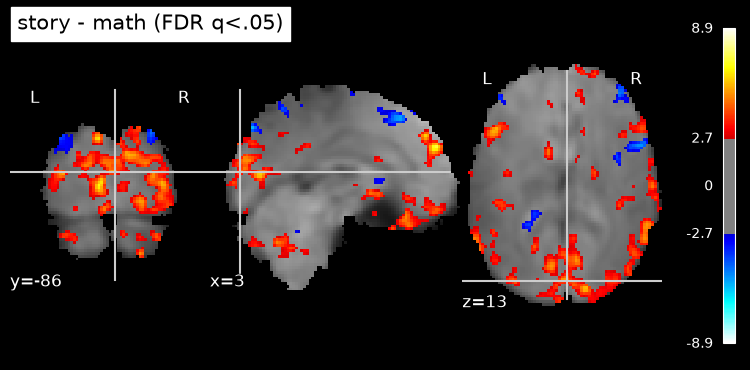

In [76]:
mean_img_ = mean_img(FMRI_SMOOTH)

plotting.plot_stat_map(thresholded_sto_min_mat, bg_img=mean_img_, threshold=thr_sto_min_math,
                           display_mode="ortho", cut_coords=None,
                           title=f"story - math (FDR q<.05)", colorbar=True)
# saving image 
plt.savefig(op.join(GLM_FIG_DIR, f"story_minus_math_zmap.png"), dpi=300, bbox_inches="tight")

### 1.3.e Networks more involved in numerical than semantic

In [48]:
# Here display clusters with yeo17 atlas